In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('placement (1).csv')

In [3]:
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


In [4]:
df.shape

(1000, 3)

<Axes: xlabel='placement_exam_marks', ylabel='Density'>

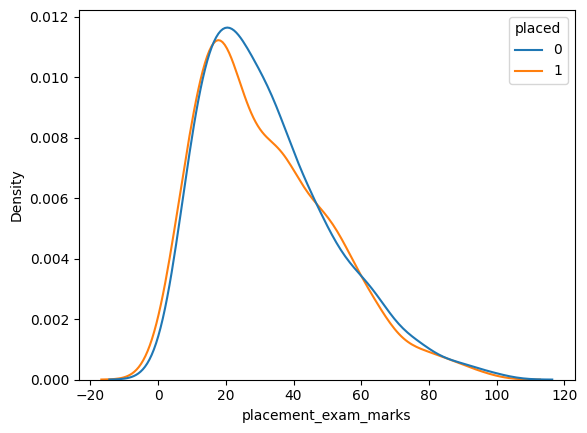

In [5]:
sns.kdeplot(data=df, x='placement_exam_marks', hue='placed')

In [6]:
df['cgpa'].describe()

count    1000.000000
mean        6.961240
std         0.615898
min         4.890000
25%         6.550000
50%         6.960000
75%         7.370000
max         9.120000
Name: cgpa, dtype: float64

In [7]:
highest_allowed = df['cgpa'].mean()+ 3*df['cgpa'].std()
lowest_allowed = df['cgpa'].mean() - 3*df['cgpa'].std()

In [8]:
print('highest_allowed : ',highest_allowed)
print('lowest_allowed : ',lowest_allowed)

highest_allowed :  8.808933625397168
lowest_allowed :  5.113546374602832


In [11]:
# find the oulier
df[(df['cgpa'] >highest_allowed) | (df['cgpa'] < lowest_allowed)]

,cgpa,placement_exam_marks,placed
485,4.92,44.0,1
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
999,4.90,10.0,1


## Trimming

In [17]:
new_df = df[(df['cgpa'] < highest_allowed) & (df['cgpa'] > lowest_allowed)]
new_df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


In [18]:
new_df['cgpa'].describe()

count    995.000000
mean       6.963357
std        0.600082
min        5.230000
25%        6.550000
50%        6.960000
75%        7.365000
max        8.620000
Name: cgpa, dtype: float64

In [19]:
new_df.shape

(995, 3)

In [20]:
# Approach 2

# Calculating the Zscore

df['cgpa_zscore'] = (df['cgpa'] - df['cgpa'].mean())/df['cgpa'].std()

In [21]:
df.head()

,cgpa,placement_exam_marks,placed,cgpa_zscore
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371


In [22]:
df[(df['cgpa_zscore'] > 3) | (df['cgpa_zscore'] < -3)]

,cgpa,placement_exam_marks,placed,cgpa_zscore
485,4.92,44.0,1,-3.314251
995,8.87,44.0,1,3.099150
996,9.12,65.0,1,3.505062
997,4.89,34.0,0,-3.362960
999,4.90,10.0,1,-3.346724


In [23]:
# Trimming 
new_df1 = df[(df['cgpa_zscore'] < 3) & (df['cgpa_zscore'] > -3)]

In [32]:
new_df1.shape

(995, 4)

In [26]:
new_df1.describe()

,cgpa,placement_exam_marks,placed,cgpa_zscore
count,995.000000,995.000000,995.000000,995.000000
mean,6.963357,32.188945,0.487437,0.003437
std,0.600082,19.130298,0.500094,0.974320
min,5.230000,0.000000,0.000000,-2.810921
25%,6.550000,17.000000,0.000000,-0.667708
50%,6.960000,28.000000,0.000000,-0.002013
75%,7.365000,44.000000,1.000000,0.655563
max,8.620000,100.000000,1.000000,2.693239


## Capping

In [27]:
upper_limit = df['cgpa'].mean() + 3*df['cgpa'].std()
lower_limit = df['cgpa'].mean() - 3*df['cgpa'].std()

In [28]:
df['cgpa'] = np.where(
    df['cgpa']>upper_limit,
    upper_limit,
    np.where(
        df['cgpa']<lower_limit,
        lower_limit,
        df['cgpa']
    )
)

In [29]:
df['cgpa'].describe()

count    1000.000000
mean        6.961499
std         0.612688
min         5.113546
25%         6.550000
50%         6.960000
75%         7.370000
max         8.808934
Name: cgpa, dtype: float64

In [31]:
df.shape

(1000, 4)